# Portfolio Risk: Historical, Parametric & Monte Carlo VaR / CVaR

This notebook measures the downside risk of a stock portfolio in three different ways and compares the results:

1. **Historical** – uses the returns that actually happened, with no assumptions about their shape.
2. **Parametric** – assumes returns follow a known distribution (normal or Student-t).
3. **Monte Carlo** – simulates hundreds of possible futures and reads the risk straight from them.

Two risk measures are reported for each method:
- **Value at Risk (VaR)** – the loss we don't expect to exceed at a given confidence level (here 95%).
- **Conditional VaR (CVaR / Expected Shortfall)** – the *average* loss on the days that are worse than the VaR.

> 💡 An interactive version of this analysis lives in `app.py` (run `streamlit run app.py`).

## 1. Load the historical data
We pull daily closing prices for six ASX-listed stocks, convert them to daily returns, and give the portfolio a random set of weights. Change the tickers or the weights to test your own allocation.

In [1]:
# Only needed on Google Colab: upgrade pandas_datareader (restart the runtime afterwards)
!pip install --upgrade pandas_datareader

In [2]:
# Core libraries: data handling, maths, statistics and plotting
import pandas as pd
import numpy as np
import datetime as dt
from pandas_datareader import data as pdr
from scipy.stats import norm, t          # normal and Student-t distributions for parametric VaR
import matplotlib.pyplot as plt

In [4]:
# yfinance replaces the Yahoo reader in pandas_datareader, which no longer works reliably
!pip install -q yfinance
import yfinance as yf

def getData(stocks, start, end):
    """Download closing prices and return (daily returns, mean daily returns, covariance matrix)."""
    stockData = yf.download(stocks, start=start, end=end)
    stockData = stockData['Close']          # keep only the closing price of each day
    returns = stockData.pct_change()        # day-to-day percentage change
    meanReturns = returns.mean()
    covMatrix = returns.cov()               # how the stocks move together
    return returns, meanReturns, covMatrix

def portfolioPerformance(weights, meanReturns, covMatrix, Time):
    """Expected return and volatility of the weighted portfolio over `Time` days."""
    returns = np.sum(meanReturns*weights)*Time                                       # return grows linearly with time
    std = np.sqrt( np.dot(weights.T, np.dot(covMatrix, weights)) ) * np.sqrt(Time)   # risk grows with sqrt(time)
    return returns, std

# Portfolio: six large ASX companies (".AX" = Australian Securities Exchange on Yahoo Finance)
stockList = ['CBA', 'BHP', 'TLS', 'NAB', 'WBC', 'STO']
stocks = [stock+'.AX' for stock in stockList]

# Use roughly the last 800 calendar days (~2 years of trading) as our history
endDate = dt.datetime.now()
startDate = endDate - dt.timedelta(days=800)

returns, meanReturns, covMatrix = getData(stocks, start=startDate, end=endDate)
returns = returns.dropna()                  # first row is NaN after pct_change

# Random weights that add up to 1 (100% of the money invested)
weights = np.random.random(len(returns.columns))
weights /= np.sum(weights)

# Daily return of the whole portfolio = weighted sum of each stock's return
returns['portfolio'] = returns.dot(weights)

/tmp/ipykernel_4880/3215506961.py:8: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stockData = yf.download(stocks, start=start, end=end)
[*********************100%***********************]  6 of 6 completed
/tmp/ipykernel_4880/3215506961.py:10: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  returns = stockData.pct_change()


## 2. Historical VaR & CVaR

The simplest approach: line up every daily portfolio return we observed, sort them, and read off the worst 5%.
No distribution is assumed – the data speaks for itself. The daily figure is then scaled to the full horizon with the square-root-of-time rule.

In [5]:
def historicalVaR(returns, alpha=5):
    """
    Historical Value at Risk.
    Accepts a Series or DataFrame of returns and returns the alpha-th percentile
    (e.g. alpha=5 -> the cut-off for the worst 5% of days, i.e. 95% confidence).
    """
    if isinstance(returns, pd.Series):
        return np.percentile(returns, alpha)

    # For a DataFrame, apply the same function to every column
    elif isinstance(returns, pd.DataFrame):
        return returns.aggregate(historicalVaR, alpha=alpha)

    else:
        raise TypeError("Expected returns to be dataframe or series")

def historicalCVaR(returns, alpha=5):
    """
    Historical Conditional VaR (Expected Shortfall).
    The average return across all days that were at or below the VaR cut-off.
    """
    if isinstance(returns, pd.Series):
        belowVaR = returns <= historicalVaR(returns, alpha=alpha)
        return returns[belowVaR].mean()

    # For a DataFrame, apply the same function to every column
    elif isinstance(returns, pd.DataFrame):
        return returns.aggregate(historicalCVaR, alpha=alpha)

    else:
        raise TypeError("Expected returns to be dataframe or series")

# Risk horizon in trading days
Time = 100

# Flip the sign so a loss is shown as a positive number, then scale daily -> 100 days
hVaR = -historicalVaR(returns['portfolio'], alpha=5)*np.sqrt(Time)
hCVaR = -historicalCVaR(returns['portfolio'], alpha=5)*np.sqrt(Time)
pRet, pStd = portfolioPerformance(weights, meanReturns, covMatrix, Time)

# Convert percentages into dollar amounts for a $10,000 portfolio
InitialInvestment = 10000
print('Expected Portfolio Return:      ', round(InitialInvestment*pRet,2))
print('Value at Risk 95th CI    :      ', round(InitialInvestment*hVaR,2))
print('Conditional VaR 95th CI  :      ', round(InitialInvestment*hCVaR,2))

Expected Portfolio Return:       667.95
Value at Risk 95th CI    :       1302.55
Conditional VaR 95th CI  :       1975.23


## 3. Parametric VaR & CVaR

Here we assume the portfolio's returns follow a known distribution and plug in the mean and standard deviation estimated above. Because the formulas are closed-form, this is very fast. Two shapes are tested:
- **Normal distribution** – the classic bell curve.
- **Student-t distribution** – similar, but with fatter tails, so extreme days are more likely. Fewer degrees of freedom (`dof`) = fatter tails.

In [6]:
def var_parametric(portofolioReturns, portfolioStd, distribution='normal', alpha=5, dof=6):
    """Parametric VaR for a normal or Student-t distribution (returned as a positive loss)."""
    if distribution == 'normal':
        # The normal distribution is symmetric, so we can use the (1 - alpha) quantile directly
        VaR = norm.ppf(1-alpha/100)*portfolioStd - portofolioReturns
    elif distribution == 't-distribution':
        nu = dof
        # sqrt((nu-2)/nu) rescales the t-distribution so its variance matches the portfolio's
        VaR = np.sqrt((nu-2)/nu) * t.ppf(1-alpha/100, nu) * portfolioStd - portofolioReturns
    else:
        raise TypeError("Expected distribution type 'normal'/'t-distribution'")
    return VaR

def cvar_parametric(portofolioReturns, portfolioStd, distribution='normal', alpha=5, dof=6):
    """Parametric CVaR (Expected Shortfall): the expected loss beyond the VaR, using closed-form formulas."""
    if distribution == 'normal':
        CVaR = (alpha/100)**-1 * norm.pdf(norm.ppf(alpha/100))*portfolioStd - portofolioReturns
    elif distribution == 't-distribution':
        nu = dof
        xanu = t.ppf(alpha/100, nu)          # alpha-quantile of the t-distribution
        CVaR = -1/(alpha/100) * (1-nu)**(-1) * (nu-2+xanu**2) * t.pdf(xanu, nu) * portfolioStd - portofolioReturns
    else:
        raise TypeError("Expected distribution type 'normal'/'t-distribution'")
    return CVaR

# Normal-distribution estimates
normVaR = var_parametric(pRet, pStd)
normCVaR = cvar_parametric(pRet, pStd)

# Student-t estimates (fatter tails)
tVaR = var_parametric(pRet, pStd, distribution='t-distribution')
tCVaR = cvar_parametric(pRet, pStd, distribution='t-distribution')

print("Normal VaR 95th CI       :      ", round(InitialInvestment*normVaR,2))
print("Normal CVaR 95th CI      :      ", round(InitialInvestment*normCVaR,2))
print("t-dist VaR 95th CI       :      ", round(InitialInvestment*tVaR,2))
print("t-dist CVaR 95th CI      :      ", round(InitialInvestment*tCVaR,2))

Normal VaR 95th CI       :       765.58
Normal CVaR 95th CI      :       1129.75
t-dist VaR 95th CI       :       714.81
t-dist CVaR 95th CI      :       1211.2


## 4. Monte Carlo VaR & CVaR

Instead of relying on a formula, we **simulate** many possible futures for the portfolio and measure the risk directly from the spread of outcomes.

How each simulated path is built:
1. Draw random standard-normal shocks for every stock on every day.
2. Use the **Cholesky decomposition** of the covariance matrix (Σ = L·Lᵀ) so the simulated stocks move together the way they did historically.
3. Add the average daily return, combine the stocks using the portfolio weights, and compound day by day.

A big advantage of this approach is flexibility: each asset could be given its own model (jumps, changing volatility, etc.) without changing the rest of the pipeline.

In [7]:
# Simulation settings
mc_sims = 400   # how many possible futures to simulate
T = 100         # horizon in trading days

# Matrix of mean daily returns, shape (n_stocks, T) - the same drift is applied every day
meanM = np.full(shape=(T, len(weights)), fill_value=meanReturns)
meanM = meanM.T

# Empty table to store results: one row per day, one column per simulation
portfolio_sims = np.full(shape=(T, mc_sims), fill_value=0.0)

initialPortfolio = 10000

# Cholesky factor of the covariance matrix - only needs to be computed once
L = np.linalg.cholesky(covMatrix)

for m in range(0, mc_sims):
    Z = np.random.normal(size=(T, len(weights)))          # independent random shocks
    dailyReturns = meanM + np.inner(L, Z)                 # correlated daily returns for each stock
    # Weighted portfolio return each day, compounded into a value path
    portfolio_sims[:,m] = np.cumprod(np.inner(weights, dailyReturns.T)+1)*initialPortfolio

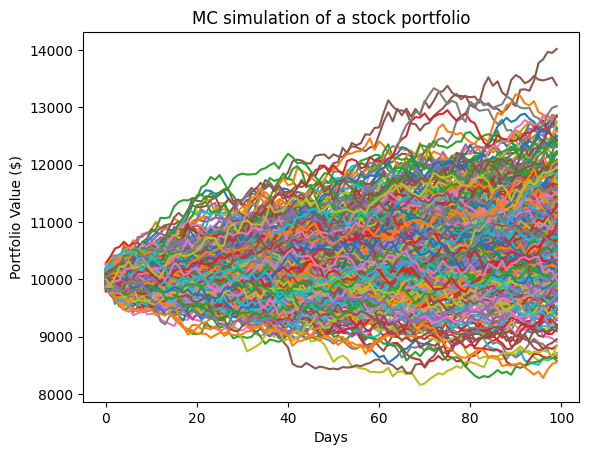

In [8]:
# Every line is one simulated future for the portfolio value
plt.plot(portfolio_sims)
plt.ylabel('Portfolio Value ($)')
plt.xlabel('Days')
plt.title('MC simulation of a stock portfolio')
plt.show()

In [9]:
def mcVaR(returns, alpha=5):
    """Monte Carlo VaR: the alpha-th percentile of the simulated ending values (pandas Series)."""
    if isinstance(returns, pd.Series):
        return np.percentile(returns, alpha)
    else:
        raise TypeError("Expected a pandas data series.")

def mcCVaR(returns, alpha=5):
    """Monte Carlo CVaR: the average ending value across the worst alpha% of simulations."""
    if isinstance(returns, pd.Series):
        belowVaR = returns <= mcVaR(returns, alpha=alpha)
        return returns[belowVaR].mean()
    else:
        raise TypeError("Expected a pandas data series.")

In [10]:
# Ending value of every simulation (the last row of the table)
portResults = pd.Series(portfolio_sims[-1,:])

# Loss = starting value minus the value at the 5th percentile / tail average
VaR = initialPortfolio - mcVaR(portResults, alpha=5)
CVaR = initialPortfolio - mcCVaR(portResults, alpha=5)

print('VaR ${}'.format(round(VaR,2)))
print('CVaR ${}'.format(round(CVaR,2)))

VaR $721.08
CVaR $1048.41


## 5. Comparing the methods

All figures below are dollar losses on a $10,000 portfolio over 100 trading days at 95% confidence.
If the historical numbers are noticeably larger than the parametric ones, real returns had fatter tails than a bell curve assumes.

In [11]:
# Side-by-side summary of every method
print("\nVaR:")

print(' historical VaR 95th CI   :      ', round(InitialInvestment*hVaR,2))
print(" Normal VaR 95th CI       :      ", round(InitialInvestment*normVaR,2))
print(" t-dist VaR 95th CI       :      ", round(InitialInvestment*tVaR,2))
print(" MC VaR  95th CI          :      ", round(VaR,2))


print("\nCVaR:")

print(' historical CVaR 95th CI  :      ', round(InitialInvestment*hCVaR,2))
print(" Normal CVaR 95th CI      :      ", round(InitialInvestment*normCVaR,2))
print(" t-dist CVaR 95th CI      :      ", round(InitialInvestment*tCVaR,2))
print(" MC CVaR 95th CI          :      ", round(CVaR,2))


VaR:
 historical VaR 95th CI   :       1302.55
 Normal VaR 95th CI       :       765.58
 t-dist VaR 95th CI       :       714.81
 MC VaR  95th CI          :       721.08

CVaR:
 historical CVaR 95th CI  :       1975.23
 Normal CVaR 95th CI      :       1129.75
 t-dist CVaR 95th CI      :       1211.2
 MC CVaR 95th CI          :       1048.41


---
*Based on the QuantPy VaR/CVaR tutorial series; comments, explanations and the dashboard were rewritten and extended for this project.*